In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    StratifiedKFold
)
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
iris = load_iris()
X = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)
y = iris.target
print("Dataset shape:", X.shape)
print("\nFlower species:")
print(iris.target_names)
print("\nFirst five rows:")
display(X.head())

Dataset shape: (150, 4)

Flower species:
['setosa' 'versicolor' 'virginica']

First five rows:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 120
Testing samples: 30


In [4]:
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier())
])
param_grid = {
    "knn__n_neighbors": range(1, 21)
}
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="accuracy",
    cv=cv,
    n_jobs=-1,
    return_train_score=True
)
grid_search.fit(X_train, y_train)
print("Best K value:", grid_search.best_params_["knn__n_neighbors"])
print(
    "Best cross-validation accuracy:",
    round(grid_search.best_score_ * 100, 2),
    "%"
)

Best K value: 3
Best cross-validation accuracy: 96.67 %


In [ ]:
results = pd.DataFrame(grid_search.cv_results_)
comparison = pd.DataFrame({
    "K Value": results["param_knn__n_neighbors"].astype(int),
    "Mean CV Accuracy (%)": (
        results["mean_test_score"] * 100
    ).round(2),
    "CV Standard Deviation (%)": (
        results["std_test_score"] * 100
    ).round(2)
})
comparison = comparison.sort_values("K Value")
display(comparison)
best_row = comparison.loc[
    comparison["Mean CV Accuracy (%)"].idxmax()
]
print("\nBest K:", best_row["K Value"])
print(
    "Mean CV accuracy:",
    best_row["Mean CV Accuracy (%)"],
    "%"
)

,K Value,Mean CV Accuracy (%),CV Standard Deviation (%)
0,1,94.17,2.04
1,2,95.00,3.12
2,3,96.67,1.67
3,4,95.83,2.64
4,5,95.83,2.64
5,6,94.17,2.04
6,7,93.33,2.04
7,8,94.17,2.04
8,9,95.83,2.64
9,10,95.83,0.00



Best K: 3.0
Mean CV accuracy: 96.67 %


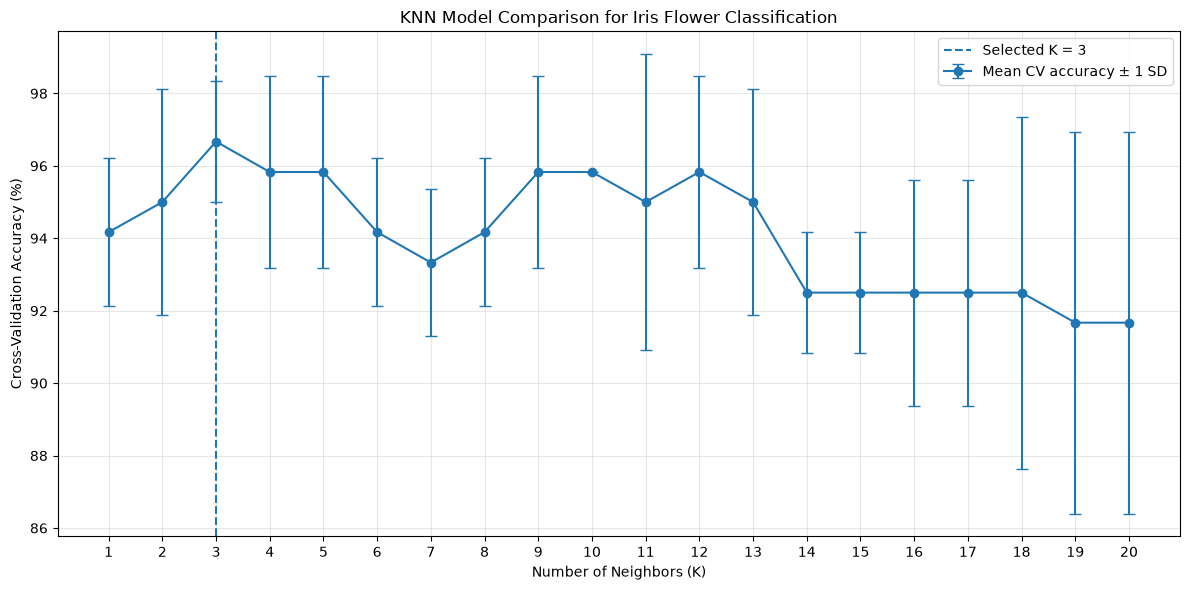

In [ ]:
plt.figure(figsize=(12, 6))
plt.errorbar(
    comparison["K Value"],
    comparison["Mean CV Accuracy (%)"],
    yerr=comparison["CV Standard Deviation (%)"],
    marker="o",
    capsize=4,
    label="Mean CV accuracy ± 1 SD"
)
best_k = grid_search.best_params_["knn__n_neighbors"]
plt.axvline(
    best_k,
    linestyle="--",
    label=f"Selected K = {best_k}"
)
plt.xticks(range(1, 21))
plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Cross-Validation Accuracy (%)")
plt.title("KNN Model Comparison for Iris Flower Classification")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)
test_accuracy = accuracy_score(y_test, y_pred)
print("Selected K:", best_k)
print(
    "Test Accuracy:",
    round(test_accuracy * 100, 2),
    "%"
)
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=iris.target_names
    )
)

Selected K: 3
Test Accuracy: 93.33 %

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



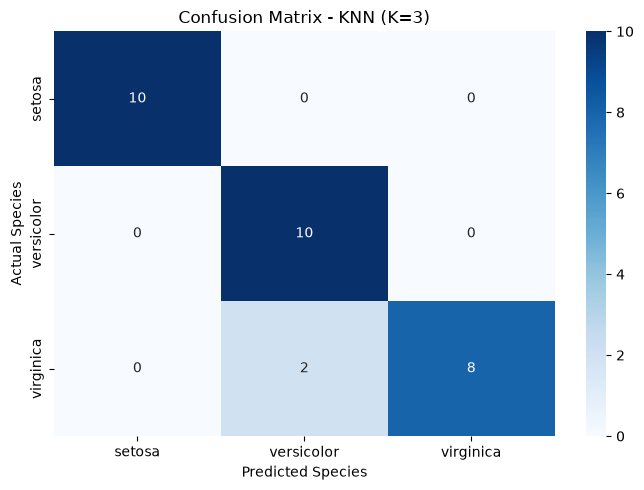

In [ ]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.title(f"Confusion Matrix - KNN (K={best_k})")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.tight_layout()
plt.show()

In [ ]:
print("FLOWER SPECIES CLASSIFICATION")
print("-----------------------------")
sepal_length = float(input("Enter sepal length (cm): "))
sepal_width = float(input("Enter sepal width (cm): "))
petal_length = float(input("Enter petal length (cm): "))
petal_width = float(input("Enter petal width (cm): "))
new_flower = pd.DataFrame(
    [[
        sepal_length,
        sepal_width,
        petal_length,
        petal_width
    ]],
    columns=iris.feature_names
)
prediction = best_model.predict(new_flower)[0]

print("\n-----------------------------")
print("FLOWER CLASSIFICATION RESULT")
print("-----------------------------")
print("Predicted Species:", iris.target_names[prediction])
print("Selected K:", best_k)
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

FLOWER SPECIES CLASSIFICATION
-----------------------------


In [ ]:
import joblib

joblib.dump(
    "flower_knn_model.pkl"
)

print("Model saved successfully!")

NameError: name 'best_model' is not defined